In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae,3))
    print("RMSE:",  round(rmse,3))
    print("R2  :",  round(r2,3))
    print("MAPE:", round(mape,2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD LSTM MODEL ----------------
def build_lstm(input_shape):
    model = Sequential([
        LSTM(96, return_sequences=True, input_shape=input_shape),
        Dropout(0.25),

        LSTM(64, return_sequences=False),
        Dropout(0.25),

        Dense(32, activation='relu'),
        Dense(2)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model


# ---------------- MAIN FUNCTION ----------------
def run_LSTM(df, name):

    print(f"\n================ LSTM for {name} ================")

    # Features and target
    X = df[['Open','High','Low','Close']].values
    y = df[['High','Low']].values

    seq_len = 25
    train_size = max(int(len(df)*0.85), seq_len+3)
    train_size = min(train_size, len(df)-2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Sequence creation
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Adaptive batch size
    batch = 16 if len(X_train)>50 else 4

    model = build_lstm((seq_len, X_train.shape[2]))

    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=batch,
        validation_data=(X_test, y_test) if len(X_test)>1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Prediction
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:,0], pred[:,1]
    true_high, true_low = y_true[:,0], y_true[:,1]

    m1 = metrics(true_high, pred_high, f"LSTM {name} High")
    m2 = metrics(true_low, pred_low, f"LSTM {name} Low")

    return (m1, m2)


In [8]:
df = pd.read_csv("crude_oil_2007_to_present.csv")
df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(",","",regex=False), errors="coerce")

df = df.sort_values("Date").fillna(method="ffill").fillna(method="bfill")
df = df[["Date","Close"]].dropna().reset_index(drop=True)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_35752\2959239312.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_35752\2959239312.py:9: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.sort_values("Date").fillna(method="ffill").fillna(method="bfill")


In [9]:
df1 = df[df["Date"].dt.year <= 2011]
df2 = df[(df["Date"].dt.year > 2011) & (df["Date"].dt.year <= 2019)]
df3 = df[(df["Date"].dt.year >= 2020) & (df["Date"].dt.year <= 2022)]
df4 = df[df["Date"].dt.year > 2022]

splits = [
    ("2007–2011", df1),
    ("2011–2019", df2),
    ("2020–2022", df3),
    ("2022–Latest", df4)
]

In [10]:
import pandas as pd

df = pd.read_csv("crude_oil_2007_to_present.csv")
print(df.columns)


Index(['Price', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')


In [18]:
df.head()

,Price,Close,High,Low,Open,Volume
0,2007-01-03,58.31999969482422,60.970001220703125,57.720001220703125,60.95000076293945,248547
1,2007-01-04,55.59000015258789,58.58000183105469,55.38999938964844,58.349998474121094,324010
2,2007-01-05,56.310001373291016,56.400001525878906,54.900001525878906,55.40999984741211,250130
3,2007-01-08,56.09000015258789,57.720001220703125,55.099998474121094,56.2400016784668,298727
4,2007-01-09,55.63999938964844,56.20000076293945,53.880001068115234,56.119998931884766,333330


In [3]:
import pandas as pd
import numpy as np

# ---------------- LOAD DATA ----------------
df = pd.read_csv("gold_2007_to_present.csv")

# The first column is actually the Date column, rename it properly
df = df.rename(columns={df.columns[0]: "Date"})

# Convert Date column to proper datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Drop invalid rows if any occurred during shifting
df = df.dropna(subset=["Date"])

# Convert numeric columns safely
for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing values created during conversion
df = df.ffill().bfill()

# Set date as index
df = df.set_index("Date")

print(df.head())
print(df.dtypes)

# ---------------- CREATE REGIME-BASED SPLITS ----------------
df1 = df.loc[: "2010-12-31"]              # Pre-2011
df2 = df.loc["2011-01-01":"2019-12-31"]   # 2011–2019
df3 = df.loc["2020-01-01":"2021-12-31"]   # COVID period
df4 = df.loc["2022-01-01":]               # 2022 onward

# Print sizes
print("\nSizes of each segment:")
print("df1 (2007–2010):", len(df1))
print("df2 (2011–2019):", len(df2))
print("df3 (2020–2021):", len(df3))
print("df4 (2022–present):", len(df4))


                 Close        High         Low        Open  Volume
Date                                                              
2007-01-02  635.200012  635.200012  635.200012  635.200012      17
2007-01-03  627.099976  640.400024  628.500000  640.400024      38
2007-01-04  623.900024  624.500000  624.500000  624.500000       4
2007-01-05  604.900024  623.700012  617.299988  623.700012     531
2007-01-08  607.500000  607.500000  607.500000  607.500000    1000
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Sizes of each segment:
df1 (2007–2010): 1009
df2 (2011–2019): 2261
df3 (2020–2021): 505
df4 (2022–present): 970


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\3444150856.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Dictionary to store all results
results = {
    "XGBoost": {},
    "CatBoost": {},
    "TCN": {},
    "ARIMA": {},
    "SARIMA": {},
    "BiLSTM": {},
    "ConvLSTM": {}
}

datasets = {
    "df1": df1,
    "df2": df2,
    "df3": df3,
    "df4": df4
}

def prepare_data(df):
    df = df.copy()

 

    # Multi-output targets
    y = df[["High", "Low"]]           # predicting both
    X = df.drop(["High", "Low"], axis=1)

    return train_test_split(X, y, test_size=0.2, random_state=42)


In [4]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

def evaluate_model(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Avoid divide-by-zero in MAPE
    non_zero_idx = y_true != 0
    mape = np.mean(np.abs((y_true[non_zero_idx] - y_pred[non_zero_idx]) / y_true[non_zero_idx])) * 100

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)

    return {
        "MAPE": mape,
        "RMSE": rmse,
        "R2": r2,
        "MAE": mae
    }


In [5]:
from xgboost import XGBRegressor

for name, df in datasets.items():
    X_train, X_test, y_train, y_test = prepare_data(df)

    model = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8
    )
    
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    results["XGBoost"][name] = {
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "R2": r2_score(y_test, preds)
    }

results["XGBoost"]


{'df1': {'RMSE': 6.168343840023817, 'R2': 0.9990535974502563},
 'df2': {'RMSE': 5.959100242646057, 'R2': 0.9990144968032837},
 'df3': {'RMSE': 9.799600273855242, 'R2': 0.9896398782730103},
 'df4': {'RMSE': 17.19842071379893, 'R2': 0.9991862773895264}}

In [6]:
from xgboost import XGBRegressor

for name, df in datasets.items():
    X_train, X_test, y_train, y_test = prepare_data(df)

    model = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6
    )

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    results["XGBoost"][name] = evaluate_model(y_test, preds)
    


In [7]:
results["XGBoost"]

{'df1': {'MAPE': 0.4716350091166879,
  'RMSE': 6.169793458524585,
  'R2': 0.9990533986703038,
  'MAE': 4.436369338838184},
 'df2': {'MAPE': 0.2803753814185316,
  'RMSE': 5.858574699472529,
  'R2': 0.9990476864785867,
  'MAE': 3.9529253220716054},
 'df3': {'MAPE': 0.33915437582803865,
  'RMSE': 9.51672049180083,
  'R2': 0.9902301251852028,
  'MAE': 5.918978549466276},
 'df4': {'MAPE': 0.3495529318804467,
  'RMSE': 18.9835426359201,
  'R2': 0.9990070718352657,
  'MAE': 8.84984816718347}}

In [8]:
from statsmodels.tsa.arima.model import ARIMA

for name, df in datasets.items():
    y = df["High"]  # choose High or Low separately

    train_size = int(len(y) * 0.8)
    train, test = y[:train_size], y[train_size:]

    model = ARIMA(train, order=(2,1,2))
    model_fit = model.fit()
    preds = model_fit.forecast(len(test))

    results["ARIMA"][name] = evaluate_model(test, preds)


d:\Anacondaa\envs\tfenv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
d:\Anacondaa\envs\tfenv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
d:\Anacondaa\envs\tfenv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
d:\Anacondaa\envs\tfenv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
d:\Anacondaa\envs\tf

In [9]:
results["ARIMA"]

{'df1': {'MAPE': 10.545246377799621,
  'RMSE': 163.67499796650466,
  'R2': -2.3108132735427467,
  'MAE': 138.48302705491383},
 'df2': {'MAPE': 6.273673198732937,
  'RMSE': 105.37688196699078,
  'R2': -0.010481944895258888,
  'MAE': 85.51033689102611},
 'df3': {'MAPE': 2.7951623016531237,
  'RMSE': 57.830059938411516,
  'R2': -3.0894167596476496,
  'MAE': 50.64446880873578},
 'df4': {'MAPE': 15.45336017495487,
  'RMSE': 658.6615141525367,
  'R2': -2.48595968890244,
  'MAE': 556.2142402588826}}

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae,3))
    print("RMSE:",  round(rmse,3))
    print("R2  :",  round(r2,3))
    print("MAPE:", round(mape,2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD BiLSTM MODEL ----------------
def build_bilstm(input_shape):
    model = Sequential([

        Bidirectional(LSTM(96, return_sequences=True), input_shape=input_shape),
        Dropout(0.25),

        Bidirectional(LSTM(64, return_sequences=False)),
        Dropout(0.25),

        Dense(32, activation='relu'),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model


# ---------------- MAIN FUNCTION ----------------
def run_BiLSTM(df, name):

    print(f"\n================ BiLSTM for {name} ================")

    # Features and target
    X = df[['Open','High','Low','Close']].values
    y = df[['High','Low']].values

    seq_len = 25
    train_size = max(int(len(df)*0.85), seq_len+3)
    train_size = min(train_size, len(df)-2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Sequence creation
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Adaptive batch size
    batch = 16 if len(X_train)>50 else 4

    model = build_bilstm((seq_len, X_train.shape[2]))

    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=batch,
        validation_data=(X_test, y_test) if len(X_test)>1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Prediction
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:,0], pred[:,1]
    true_high, true_low = y_true[:,0], y_true[:,1]

    m1 = metrics(true_high, pred_high, f"BiLSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"BiLSTM {name} Low")

    return (m1, m2)


In [12]:
# ================= RUN BILSTM ON ALL DATASETS ================= #

# df1, df2, df3, df4 must already be loaded before running this cell.

print("\n\n====== RUNNING BiLSTM ON ALL DATASETS ======\n")

results_bilstm = {}

for df, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training BiLSTM for {name} -----")
    try:
        res = run_BiLSTM(df, name)
        results_bilstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL BiLSTM RESULTS =============\n")
results_bilstm




====== RUNNING BiLSTM ON ALL DATASETS ======



----- Training BiLSTM for DF1 -----

================ BiLSTM for DF1 ================


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - loss: 0.0939 - val_loss: 0.2932 - learning_rate: 0.0010
Epoch 2/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0418 - val_loss: 0.1635 - learning_rate: 0.0010
Epoch 3/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0318 - val_loss: 0.2034 - learning_rate: 0.0010
Epoch 4/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0318 - val_loss: 0.1537 - learning_rate: 0.0010
Epoch 5/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0236 - val_loss: 0.2159 - learning_rate: 0.0010
Epoch 6/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0260 - val_loss: 0.1405 - learning_rate: 0.0010
Epoch 7/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0201 - val_loss: 0.1089 - learning_rate: 0.0010
Epoch 8/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0210 - val_loss: 0.1263 - learning_rate: 0.0010
Epoch 9/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0190 - val_loss: 0.1307 - learning_rate: 0.0010
Epoch 10/60
52/52 ━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.0661 - val_loss: 0.0096 - learning_rate: 0.0010
Epoch 2/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0245 - val_loss: 0.0068 - learning_rate: 0.0010
Epoch 3/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0221 - val_loss: 0.0112 - learning_rate: 0.0010
Epoch 4/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0188 - val_loss: 0.0074 - learning_rate: 0.0010
Epoch 5/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0195 - val_loss: 0.0057 - learning_rate: 0.0010
Epoch 6/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0166 - val_loss: 0.0067 - learning_rate: 0.0010
Epoch 7/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0150 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 8/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0149 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 9/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0147 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 10/60


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.2974 - val_loss: 0.0508 - learning_rate: 0.0010
Epoch 2/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1518 - val_loss: 0.0383 - learning_rate: 0.0010
Epoch 3/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1064 - val_loss: 0.0446 - learning_rate: 0.0010
Epoch 4/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1046 - val_loss: 0.0330 - learning_rate: 0.0010
Epoch 5/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0831 - val_loss: 0.0260 - learning_rate: 0.0010
Epoch 6/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0766 - val_loss: 0.0262 - learning_rate: 0.0010
Epoch 7/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0736 - val_loss: 0.0241 - learning_rate: 0.0010
Epoch 8/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0698 - val_loss: 0.0229 - learning_rate: 0.0010
Epoch 9/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0644 - val_loss: 0.0234 - learning_rate: 0.0010
Epoch 10/60
26/26 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.1840 - val_loss: 2.0882 - learning_rate: 0.0010
Epoch 2/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0306 - val_loss: 1.5924 - learning_rate: 0.0010
Epoch 3/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0214 - val_loss: 1.0394 - learning_rate: 0.0010
Epoch 4/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0195 - val_loss: 1.1359 - learning_rate: 0.0010
Epoch 5/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0204 - val_loss: 0.9566 - learning_rate: 0.0010
Epoch 6/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0167 - val_loss: 0.8160 - learning_rate: 0.0010
Epoch 7/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0199 - val_loss: 0.9148 - learning_rate: 0.0010
Epoch 8/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0167 - val_loss: 0.6896 - learning_rate: 0.0010
Epoch 9/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0130 - val_loss: 0.6708 - learning_rate: 0.0010
Epoch 10/60
50/50 ━━━━━━━━━━━━━━━━━━━

{'DF1': {'High': {'MAE': 30.46076322856702,
   'RMSE': 38.915283402525596,
   'R2': 0.7491573512043591,
   'MAPE': 2.2766183582993036},
  'Low': {'MAE': 29.05877765856291,
   'RMSE': 37.20260080505371,
   'R2': 0.751991672791098,
   'MAPE': 2.1932237588457135}},
 'DF2': {'High': {'MAE': 7.15313720703125,
   'RMSE': 9.479759553167543,
   'R2': 0.9928868142864699,
   'MAPE': 0.5249245288126392},
  'Low': {'MAE': 6.844464111328125,
   'RMSE': 8.860936209688656,
   'R2': 0.9933975066578595,
   'MAPE': 0.5062199860495765}},
 'DF3': {'High': {'MAE': 12.0676124974301,
   'RMSE': 15.614294654878345,
   'R2': 0.7340260505839157,
   'MAPE': 0.6704887730170865},
  'Low': {'MAE': 11.770662006578945,
   'RMSE': 16.378186017589826,
   'R2': 0.7457722029293776,
   'MAPE': 0.6600939194652367}},
 'DF4': {'High': {'MAE': 147.50923219445633,
   'RMSE': 225.01494643451656,
   'R2': 0.4283220247967432,
   'MAPE': 3.8383636208223817},
  'Low': {'MAE': 150.03586358893406,
   'RMSE': 234.96671285167207,
   'R

In [13]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tcn import TCN


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae,3))
    print("RMSE:",  round(rmse,3))
    print("R2  :",  round(r2,3))
    print("MAPE:", round(mape,2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD TCN MODEL ----------------
def build_tcn(input_shape):
    model = Sequential([

        TCN(nb_filters=64,
            kernel_size=3,
            dilations=[1, 2, 4, 8, 16],
            dropout_rate=0.25,
            return_sequences=False,
            activation='relu',
            input_shape=input_shape),

        Dense(32, activation='relu'),
        Dropout(0.25),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model


# ---------------- MAIN TCN FUNCTION ----------------
def run_TCN(df, name):

    print(f"\n================ TCN for {name} ================")

    # Features and target
    X = df[['Open','High','Low','Close']].values
    y = df[['High','Low']].values

    seq_len = 25
    train_size = max(int(len(df)*0.85), seq_len+3)
    train_size = min(train_size, len(df)-2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Sequence creation
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len

    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    batch = 16 if len(X_train)>50 else 4

    model = build_tcn((seq_len, X_train.shape[2]))

    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=batch,
        validation_data=(X_test, y_test) if len(X_test)>1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Prediction
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:,0], pred[:,1]
    true_high, true_low = y_true[:,0], y_true[:,1]

    m1 = metrics(true_high, pred_high, f"TCN {name} High")
    m2 = metrics(true_low,  pred_low,  f"TCN {name} Low")

    return (m1, m2)


In [14]:
results_tcn = {}

for df, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training TCN for {name} -----")
    try:
        res = run_TCN(df, name)
        results_tcn[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

results_tcn




----- Training TCN for DF1 -----

================ TCN for DF1 ================


d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)



Epoch 1/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 16.3546 - val_loss: 2.0146 - learning_rate: 0.0010
Epoch 2/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.5556 - val_loss: 2.4925 - learning_rate: 0.0010
Epoch 3/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9944 - val_loss: 2.5885 - learning_rate: 0.0010
Epoch 4/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6687 - val_loss: 1.9747 - learning_rate: 0.0010
Epoch 5/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5886 - val_loss: 1.8005 - learning_rate: 0.0010
Epoch 6/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5301 - val_loss: 1.0861 - learning_rate: 0.0010
Epoch 7/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4075 - val_loss: 0.7277 - learning_rate: 0.0010
Epoch 8/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4202 - val_loss: 0.9743 - learning_rate: 0.0010
Epoch 9/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3855 - val_loss: 0.7508 - learning_rate: 0.0010
Epoch 10/60
52/52 ━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 6.1755 - val_loss: 0.1328 - learning_rate: 0.0010
Epoch 2/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.7578 - val_loss: 0.0707 - learning_rate: 0.0010
Epoch 3/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4845 - val_loss: 0.0514 - learning_rate: 0.0010
Epoch 4/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3667 - val_loss: 0.0564 - learning_rate: 0.0010
Epoch 5/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3099 - val_loss: 0.0497 - learning_rate: 0.0010
Epoch 6/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2737 - val_loss: 0.0486 - learning_rate: 0.0010
Epoch 7/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2264 - val_loss: 0.0452 - learning_rate: 0.0010
Epoch 8/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2265 - val_loss: 0.0417 - learning_rate: 0.0010
Epoch 9/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2101 - val_loss: 0.0179 - learning_rate: 0.0010
Epoch 10/60
119/119 

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 15.1176 - val_loss: 0.0851 - learning_rate: 0.0010
Epoch 2/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.7182 - val_loss: 0.0632 - learning_rate: 0.0010
Epoch 3/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.2159 - val_loss: 0.0527 - learning_rate: 0.0010
Epoch 4/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.9966 - val_loss: 0.0571 - learning_rate: 0.0010
Epoch 5/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.8161 - val_loss: 0.0551 - learning_rate: 0.0010
Epoch 6/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5826 - val_loss: 0.0504 - learning_rate: 0.0010
Epoch 7/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5640 - val_loss: 0.0487 - learning_rate: 0.0010
Epoch 8/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4421 - val_loss: 0.0458 - learning_rate: 0.0010
Epoch 9/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4576 - val_loss: 0.0435 - learning_rate: 0.0010
Epoch 10/60
26/26 ━━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Epoch 1/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 14.4681 - val_loss: 7.8828 - learning_rate: 0.0010
Epoch 2/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.5346 - val_loss: 8.5461 - learning_rate: 0.0010
Epoch 3/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8364 - val_loss: 8.5883 - learning_rate: 0.0010
Epoch 4/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.6412 - val_loss: 6.5734 - learning_rate: 0.0010
Epoch 5/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6267 - val_loss: 3.0923 - learning_rate: 0.0010
Epoch 6/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4865 - val_loss: 3.3288 - learning_rate: 0.0010
Epoch 7/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3987 - val_loss: 3.0167 - learning_rate: 0.0010
Epoch 8/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3521 - val_loss: 4.0243 - learning_rate: 0.0010
Epoch 9/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3214 - val_loss: 2.9893 - learning_rate: 0.0010
Epoch 10/60
50/50 ━━━━━━━━

{'DF1': {'High': {'MAE': 161.80542714972245,
   'RMSE': 165.7310266710504,
   'R2': -3.5495519076445587,
   'MAPE': 12.392682067859255},
  'Low': {'MAE': 68.95254677220395,
   'RMSE': 73.94203889429949,
   'R2': 0.02027880784980629,
   'MAPE': 5.325821772203776}},
 'DF2': {'High': {'MAE': 13.820647475298713,
   'RMSE': 18.240618591944713,
   'R2': 0.9736640718592184,
   'MAPE': 1.0177803892442387},
  'Low': {'MAE': 13.325980152803309,
   'RMSE': 17.65342257961863,
   'R2': 0.9737936470180917,
   'MAPE': 0.9718097214162811}},
 'DF3': {'High': {'MAE': 13.333510549444895,
   'RMSE': 16.954808731828326,
   'R2': 0.6863970418863357,
   'MAPE': 0.7422400327412586},
  'Low': {'MAE': 14.036670885587984,
   'RMSE': 17.06303180820282,
   'R2': 0.724066877034405,
   'MAPE': 0.7885445238418651}},
 'DF4': {'High': {'MAE': 341.1047981993793,
   'RMSE': 362.55477263934074,
   'R2': -0.48414379342867764,
   'MAPE': 9.465147449744386},
  'Low': {'MAE': 495.82119876391266,
   'RMSE': 512.7052318888528,


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau



# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)



# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- BUILD LSTM MODEL ----------------
def build_lstm(input_shape):

    model = Sequential([

        LSTM(96, return_sequences=True, input_shape=input_shape),
        Dropout(0.25),

        LSTM(64, return_sequences=False),
        Dropout(0.25),

        Dense(32, activation='relu'),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN FUNCTION ----------------
def run_LSTM(df, name):

    print(f"\n================ LSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Adaptive batch size
    batch_size = 16 if len(X_train) > 50 else 4

    # Build model
    model = build_lstm((seq_len, X_train.shape[2]))

    # Callbacks
    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train
    model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=batch_size,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Prediction
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"LSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"LSTM {name} Low")

    return (m1, m2)



# ================= RUN LSTM ON ALL DATASETS ================= #

print("\n\n====== RUNNING LSTM ON ALL DATASETS ======\n")

results_lstm = {}

# df1, df2, df3, df4 must already be defined
for df, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training LSTM for {name} -----")
    try:
        res = run_LSTM(df, name)
        results_lstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL LSTM RESULTS =============\n")
results_lstm




====== RUNNING LSTM ON ALL DATASETS ======



----- Training LSTM for DF1 -----

================ LSTM for DF1 ================
Epoch 1/60


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.1669 - val_loss: 0.4689 - learning_rate: 0.0010
Epoch 2/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0449 - val_loss: 0.4615 - learning_rate: 0.0010
Epoch 3/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0406 - val_loss: 0.4098 - learning_rate: 0.0010
Epoch 4/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0331 - val_loss: 0.2023 - learning_rate: 0.0010
Epoch 5/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0346 - val_loss: 0.3300 - learning_rate: 0.0010
Epoch 6/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0317 - val_loss: 0.4005 - learning_rate: 0.0010
Epoch 7/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0308 - val_loss: 0.1467 - learning_rate: 0.0010
Epoch 8/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0257 - val_loss: 0.1202 - learning_rate: 0.0010
Epoch 9/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0260 - val_loss: 0.1954 - learning_rate: 0.0010
Epoch 10/60
52/52 ━━━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.1022 - val_loss: 0.0093 - learning_rate: 0.0010
Epoch 2/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0326 - val_loss: 0.0082 - learning_rate: 0.0010
Epoch 3/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0299 - val_loss: 0.0067 - learning_rate: 0.0010
Epoch 4/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0251 - val_loss: 0.0058 - learning_rate: 0.0010
Epoch 5/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0243 - val_loss: 0.0062 - learning_rate: 0.0010
Epoch 6/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0205 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 7/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0193 - val_loss: 0.0059 - learning_rate: 0.0010
Epoch 8/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0202 - val_loss: 0.0061 - learning_rate: 0.0010
Epoch 9/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0185 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 10/60
119/119 ━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.3256 - val_loss: 0.0607 - learning_rate: 0.0010
Epoch 2/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1365 - val_loss: 0.0467 - learning_rate: 0.0010
Epoch 3/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1277 - val_loss: 0.0414 - learning_rate: 0.0010
Epoch 4/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1110 - val_loss: 0.0312 - learning_rate: 0.0010
Epoch 5/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1012 - val_loss: 0.0338 - learning_rate: 0.0010
Epoch 6/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0972 - val_loss: 0.0342 - learning_rate: 0.0010
Epoch 7/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0913 - val_loss: 0.0258 - learning_rate: 0.0010
Epoch 8/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0867 - val_loss: 0.0265 - learning_rate: 0.0010
Epoch 9/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0868 - val_loss: 0.0257 - learning_rate: 0.0010
Epoch 10/60
26/26 ━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1660 - val_loss: 2.0764 - learning_rate: 0.0010
Epoch 2/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0322 - val_loss: 1.3791 - learning_rate: 0.0010
Epoch 3/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0321 - val_loss: 1.1085 - learning_rate: 0.0010
Epoch 4/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0251 - val_loss: 1.0626 - learning_rate: 0.0010
Epoch 5/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0281 - val_loss: 1.1118 - learning_rate: 0.0010
Epoch 6/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0228 - val_loss: 0.9118 - learning_rate: 0.0010
Epoch 7/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0250 - val_loss: 0.9922 - learning_rate: 0.0010
Epoch 8/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0186 - val_loss: 0.6893 - learning_rate: 0.0010
Epoch 9/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0175 - val_loss: 0.5758 - learning_rate: 0.0010
Epoch 10/60
50/50 ━━━━━━━━━━━━━━━━━━━━

{'DF1': {'High': {'MAE': 27.711849011872943,
   'RMSE': 36.612216197810056,
   'R2': 0.7779693044472344,
   'MAPE': 2.0616771150482345},
  'Low': {'MAE': 30.440773411800986,
   'RMSE': 40.23127150610587,
   'R2': 0.7099671594284663,
   'MAPE': 2.2806980065377926}},
 'DF2': {'High': {'MAE': 7.8130722943474264,
   'RMSE': 10.150959378588546,
   'R2': 0.991843878562979,
   'MAPE': 0.5755689500424426},
  'Low': {'MAE': 7.669440056295956,
   'RMSE': 9.802478042318493,
   'R2': 0.9919198298129385,
   'MAPE': 0.5685337544567696}},
 'DF3': {'High': {'MAE': 11.049513967413658,
   'RMSE': 14.407605987057911,
   'R2': 0.7735470372475217,
   'MAPE': 0.6143578783479722},
  'Low': {'MAE': 11.226690995065793,
   'RMSE': 14.906082387087272,
   'R2': 0.7894193460372172,
   'MAPE': 0.6308971878889665}},
 'DF4': {'High': {'MAE': 159.1779651380565,
   'RMSE': 244.28554198659765,
   'R2': 0.32621047446654816,
   'MAPE': 4.137783062405376},
  'Low': {'MAE': 167.80884959599743,
   'RMSE': 262.3248743348272,


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ConvLSTM2D, Dropout, Flatten, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau



# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)



# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- BUILD ConvLSTM MODEL ----------------
def build_convlstm(input_shape):

    model = Sequential([

        ConvLSTM2D(
            filters=64,
            kernel_size=(1, 2),
            return_sequences=True,
            activation='tanh',
            padding='same',
            input_shape=input_shape
        ),
        Dropout(0.25),

        ConvLSTM2D(
            filters=32,
            kernel_size=(1, 2),
            return_sequences=False,
            activation='tanh',
            padding='same'
        ),
        Dropout(0.25),

        Flatten(),

        Dense(64, activation='relu'),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN FUNCTION ----------------
def run_ConvLSTM(df, name):

    print(f"\n================ ConvLSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge for sequence creation
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Split into train/test
    split = train_size - seq_len
    X_train_seq, X_test_seq = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # ConvLSTM requires 5D input: (batch, seq_len, spatial_x, spatial_y, channels)
    X_train = X_train_seq.reshape(-1, seq_len, 1, X_train_raw.shape[1], 1)
    X_test  = X_test_seq.reshape(-1, seq_len, 1, X_train_raw.shape[1], 1)

    # Adaptive batch size
    batch_size = 8 if len(X_train) > 50 else 2

    # Build model
    model = build_convlstm((seq_len, 1, X_train_raw.shape[1], 1))

    # Callbacks
    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train model
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=batch_size,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"ConvLSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"ConvLSTM {name} Low")

    return (m1, m2)



# ================= RUN ConvLSTM ON ALL DATASETS ================= #
print("\n\n====== RUNNING ConvLSTM ON ALL DATASETS ======\n")

results_convlstm = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training ConvLSTM for {name} -----")
    try:
        res = run_ConvLSTM(df_regime, name)
        results_convlstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL ConvLSTM RESULTS =============\n")
results_convlstm




====== RUNNING ConvLSTM ON ALL DATASETS ======



----- Training ConvLSTM for DF1 -----

================ ConvLSTM for DF1 ================
Epoch 1/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0931 - val_loss: 0.2053 - learning_rate: 0.0010
Epoch 2/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0364 - val_loss: 0.0807 - learning_rate: 0.0010
Epoch 3/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0314 - val_loss: 0.1678 - learning_rate: 0.0010
Epoch 4/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0269 - val_loss: 0.3695 - learning_rate: 0.0010
Epoch 5/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0228 - val_loss: 0.1714 - learning_rate: 0.0010
Epoch 6/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0209 - val_loss: 0.0512 - learning_rate: 5.0000e-04
Epoch 7/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0173 - val_loss: 0.0718 - learning_rate: 5.0000e-04
Epoch 8/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0181 - val_loss: 0.0729 - learning_rate: 5.0000e-04
Epoch 9/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0186 - val_loss: 0.0164 - learning_rate: 5.0000e

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


237/237 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.0609 - val_loss: 0.0097 - learning_rate: 0.0010
Epoch 2/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0246 - val_loss: 0.0063 - learning_rate: 0.0010
Epoch 3/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0216 - val_loss: 0.0053 - learning_rate: 0.0010
Epoch 4/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0178 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 5/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0175 - val_loss: 0.0056 - learning_rate: 0.0010
Epoch 6/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0172 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 7/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0136 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 8/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0123 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 9/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0121 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 10/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.2590 - val_loss: 0.0605 - learning_rate: 0.0010
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1134 - val_loss: 0.0411 - learning_rate: 0.0010
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1078 - val_loss: 0.0361 - learning_rate: 0.0010
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0955 - val_loss: 0.0308 - learning_rate: 0.0010
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0835 - val_loss: 0.0289 - learning_rate: 0.0010
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0840 - val_loss: 0.0257 - learning_rate: 0.0010
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0794 - val_loss: 0.0236 - learning_rate: 0.0010
Epoch 8/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0709 - val_loss: 0.0227 - learning_rate: 0.0010
Epoch 9/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0650 - val_loss: 0.0291 - learning_rate: 0.0010
Epoch 10/50
51/51 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0988 - val_loss: 0.9628 - learning_rate: 0.0010
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0256 - val_loss: 0.8518 - learning_rate: 0.0010
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0210 - val_loss: 0.5132 - learning_rate: 0.0010
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0191 - val_loss: 0.1768 - learning_rate: 0.0010
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0167 - val_loss: 0.1705 - learning_rate: 0.0010
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0155 - val_loss: 0.4799 - learning_rate: 0.0010
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0181 - val_loss: 0.3424 - learning_rate: 0.0010
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0159 - val_loss: 0.3440 - learning_rate: 0.0010
Epoch 9/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0127 - val_loss: 0.1047 - learning_rate: 5.0000e-04
Epoch 10

{'DF1': {'High': {'MAE': 11.671992251747533,
   'RMSE': 15.39974555709335,
   'R2': 0.9607184990868299,
   'MAPE': 0.8905428629392821},
  'Low': {'MAE': 10.872221294202303,
   'RMSE': 13.59986408912935,
   'R2': 0.9668572305849173,
   'MAPE': 0.8393935167132067}},
 'DF2': {'High': {'MAE': 7.516873348460478,
   'RMSE': 9.589673301086437,
   'R2': 0.9927209093542084,
   'MAPE': 0.5528539117998033},
  'Low': {'MAE': 6.469002757352941,
   'RMSE': 8.559328510180167,
   'R2': 0.9938393272223799,
   'MAPE': 0.47937908130456414}},
 'DF3': {'High': {'MAE': 10.035051847759052,
   'RMSE': 12.683617095660829,
   'R2': 0.8244985915016425,
   'MAPE': 0.557886510860215},
  'Low': {'MAE': 10.916632401315793,
   'RMSE': 14.48120186263209,
   'R2': 0.8012529686138876,
   'MAPE': 0.6137404429838167}},
 'DF4': {'High': {'MAE': 68.43718897153254,
   'RMSE': 91.78084386093336,
   'R2': 0.9048885461972002,
   'MAPE': 1.8871346725885463},
  'Low': {'MAE': 64.52789390250427,
   'RMSE': 83.91998075167916,
   'R

In [17]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from catboost import CatBoostRegressor


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i].flatten())  # Flatten for CatBoost
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD & RUN CATBOOST MODEL ----------------
def run_CatBoost(df, name):

    print(f"\n================ CatBoost for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge for sequence creation
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Split into train/test
    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # ---------------- CatBoost Model ----------------
    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=8,
        loss_function='MultiRMSE',
        verbose=False
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"CatBoost {name} High")
    m2 = metrics(true_low,  pred_low,  f"CatBoost {name} Low")

    return (m1, m2)



# ================= RUN CATBOOST ON ALL DATASETS ================= #

print("\n\n====== RUNNING CatBoost ON ALL DATASETS ======\n")

results_catboost = {}

# df1, df2, df3, df4 must already be created before this
for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training CatBoost for {name} -----")
    try:
        res = run_CatBoost(df_regime, name)
        results_catboost[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL CatBoost RESULTS =============\n")
results_catboost




====== RUNNING CatBoost ON ALL DATASETS ======



----- Training CatBoost for DF1 -----

================ CatBoost for DF1 ================

===== CatBoost DF1 High =====
MAE : 84.849
RMSE: 111.075
R2  : -1.044
MAPE: 6.26 %

===== CatBoost DF1 Low =====
MAE : 75.497
RMSE: 99.879
R2  : -0.788
MAPE: 5.63 %


----- Training CatBoost for DF2 -----

================ CatBoost for DF2 ================

===== CatBoost DF2 High =====
MAE : 9.059
RMSE: 12.161
R2  : 0.988
MAPE: 0.66 %

===== CatBoost DF2 Low =====
MAE : 8.768
RMSE: 11.644
R2  : 0.989
MAPE: 0.64 %


----- Training CatBoost for DF3 -----

================ CatBoost for DF3 ================

===== CatBoost DF3 High =====
MAE : 11.686
RMSE: 14.956
R2  : 0.756
MAPE: 0.65 %

===== CatBoost DF3 Low =====
MAE : 10.229
RMSE: 14.904
R2  : 0.789
MAPE: 0.57 %


----- Training CatBoost for DF4 -----

================ CatBoost for DF4 ================

===== CatBoost DF4 High =====
MAE : 344.661
RMSE: 455.209
R2  : -1.34
MAPE: 9.13 %

===== C

{'DF1': {'High': {'MAE': 84.84908816200532,
   'RMSE': 111.07452851478263,
   'R2': -1.0435719824771699,
   'MAPE': 6.2580634337170995},
  'Low': {'MAE': 75.49663544262633,
   'RMSE': 99.87863667096451,
   'R2': -0.7875774609997899,
   'MAPE': 5.629347419939372}},
 'DF2': {'High': {'MAE': 9.059494688965536,
   'RMSE': 12.160641493685477,
   'R2': 0.9882947020113715,
   'MAPE': 0.6569279076928647},
  'Low': {'MAE': 8.767930520062006,
   'RMSE': 11.643959153532842,
   'R2': 0.9885988122269507,
   'MAPE': 0.6431422575141161}},
 'DF3': {'High': {'MAE': 11.685758561736646,
   'RMSE': 14.955950380155349,
   'R2': 0.75598170285031,
   'MAPE': 0.6494723145273689},
  'Low': {'MAE': 10.229243604548,
   'RMSE': 14.903644356165115,
   'R2': 0.7894882253237724,
   'MAPE': 0.5748607534048208}},
 'DF4': {'High': {'MAE': 344.6612900182147,
   'RMSE': 455.20881097884757,
   'R2': -1.3396454342624273,
   'MAPE': 9.13417843948939},
  'Low': {'MAE': 375.885431959526,
   'RMSE': 471.1035820444804,
   'R2':

In [3]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor

from xgboost import XGBRegressor


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i].flatten())  # flatten for XGBoost
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD & RUN XGBOOST MODEL ----------------
def run_XGBoost(df, name):

    print(f"\n================ XGBoost for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values   # Multi-output prediction

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Sequence creation
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]


    # ---------------- XGBoost Model ----------------
    model = MultiOutputRegressor(
        XGBRegressor(
            n_estimators=600,
            learning_rate=0.05,
            max_depth=8,
            subsample=0.9,
            colsample_bytree=0.9,
            objective='reg:squarederror',
            tree_method="hist",
            eval_metric="rmse"
        )
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"XGBoost {name} High")
    m2 = metrics(true_low, pred_low,  f"XGBoost {name} Low")

    return (m1, m2)




# ================= RUN XGBOOST ON ALL DATASETS ================= #

print("\n\n====== RUNNING XGBoost ON ALL DATASETS ======\n")

results_xgboost = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training XGBoost for {name} -----")
    try:
        res = run_XGBoost(df_regime, name)
        results_xgboost[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL XGBoost RESULTS =============\n")
results_xgboost




====== RUNNING XGBoost ON ALL DATASETS ======



----- Training XGBoost for DF1 -----

================ XGBoost for DF1 ================

===== XGBoost DF1 High =====
MAE : 89.624
RMSE: 116.399
R2  : -1.244
MAPE: 6.61 %

===== XGBoost DF1 Low =====
MAE : 69.725
RMSE: 95.025
R2  : -0.618
MAPE: 5.18 %


----- Training XGBoost for DF2 -----

================ XGBoost for DF2 ================

===== XGBoost DF2 High =====
MAE : 7.784
RMSE: 10.246
R2  : 0.992
MAPE: 0.57 %

===== XGBoost DF2 Low =====
MAE : 7.888
RMSE: 10.093
R2  : 0.991
MAPE: 0.58 %


----- Training XGBoost for DF3 -----

================ XGBoost for DF3 ================

===== XGBoost DF3 High =====
MAE : 10.697
RMSE: 13.948
R2  : 0.788
MAPE: 0.59 %

===== XGBoost DF3 Low =====
MAE : 11.479
RMSE: 15.269
R2  : 0.779
MAPE: 0.65 %


----- Training XGBoost for DF4 -----

================ XGBoost for DF4 ================

===== XGBoost DF4 High =====
MAE : 338.357
RMSE: 450.201
R2  : -1.288
MAPE: 8.96 %

===== XGBoost DF4 Low 

{'DF1': {'High': {'MAE': 89.62401861893504,
   'RMSE': 116.39935687634156,
   'R2': -1.2442030306651755,
   'MAPE': 6.612918669190634},
  'Low': {'MAE': 69.72509444387336,
   'RMSE': 95.02475651819289,
   'R2': -0.6180546645660623,
   'MAPE': 5.1792089461222135}},
 'DF2': {'High': {'MAE': 7.784325453814338,
   'RMSE': 10.24564188660427,
   'R2': 0.9916910174339623,
   'MAPE': 0.5660807784553643},
  'Low': {'MAE': 7.887572524126838,
   'RMSE': 10.093373946572378,
   'R2': 0.9914331437610989,
   'MAPE': 0.5821755483468067}},
 'DF3': {'High': {'MAE': 10.696674547697375,
   'RMSE': 13.948244577861809,
   'R2': 0.787756954446875,
   'MAPE': 0.5937166986380128},
  'Low': {'MAE': 11.47905691046464,
   'RMSE': 15.268625365818522,
   'R2': 0.7790513694750529,
   'MAPE': 0.6468337349949997}},
 'DF4': {'High': {'MAE': 338.35679981806504,
   'RMSE': 450.2013366534382,
   'R2': -1.288454528246311,
   'MAPE': 8.95618353936004},
  'Low': {'MAE': 364.2094642952697,
   'RMSE': 461.4021414900153,
   'R2

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)



# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2  :", round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- BUILD Conv1D + LSTM MODEL ----------------
def build_conv_lstm_model(seq_len, num_features):

    model = Sequential([
        Conv1D(filters=64, kernel_size=3, activation='relu', padding='same',
               input_shape=(seq_len, num_features)),
        Dropout(0.2),

        Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
        Dropout(0.2),

        LSTM(64, return_sequences=False),
        Dropout(0.2),

        Dense(32, activation='relu'),
        Dense(2)   # Output: High, Low
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN FUNCTION ----------------
def run_ConvLSTM(df, name):

    print(f"\n================ Conv1D-LSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    # Scale data
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y)

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Dataset split
    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    print("Training samples:", len(X_train), " | Testing samples:", len(X_test))

    # Build model
    model = build_conv_lstm_model(seq_len, X.shape[1])

    # Callbacks
    es = EarlyStopping(patience=8, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=4)

    # Train model
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=16,
        validation_data=(X_test, y_test),
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"ConvLSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"ConvLSTM {name} Low")

    return (m1, m2)



# ================= RUN ConvLSTM ON ALL DATASETS ================= #
print("\n\n====== RUNNING Conv1D-LSTM ON ALL DATASETS ======\n")

results_convlstm = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training Conv1D-LSTM for {name} -----")
    try:
        res = run_ConvLSTM(df_regime, name)
        results_convlstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL Conv1D-LSTM RESULTS =============\n")
results_convlstm




====== RUNNING Conv1D-LSTM ON ALL DATASETS ======



----- Training Conv1D-LSTM for DF1 -----

================ Conv1D-LSTM for DF1 ================
Training samples: 832  | Testing samples: 152
Epoch 1/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1341 - val_loss: 0.2406 - learning_rate: 0.0010
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0221 - val_loss: 0.1706 - learning_rate: 0.0010
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0219 - val_loss: 0.2322 - learning_rate: 0.0010
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0199 - val_loss: 0.1874 - learning_rate: 0.0010
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0160 - val_loss: 0.1709 - learning_rate: 0.0010
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0165 - val_loss: 0.1115 - learning_rate: 0.0010
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0147 - val_loss: 0.1173 - learning_rate: 0.0010
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0156 - val_loss: 0.3009 - learning_rate: 0.0010
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0144 - val_loss: 0.2195 - learning_rate: 0.0010
Epoch 10/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1328 - val_loss: 0.0088 - learning_rate: 0.0010
Epoch 2/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0340 - val_loss: 0.0077 - learning_rate: 0.0010
Epoch 3/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0307 - val_loss: 0.0079 - learning_rate: 0.0010
Epoch 4/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0337 - val_loss: 0.0060 - learning_rate: 0.0010
Epoch 5/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0274 - val_loss: 0.0057 - learning_rate: 0.0010
Epoch 6/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0249 - val_loss: 0.0070 - learning_rate: 0.0010
Epoch 7/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0298 - val_loss: 0.0053 - learning_rate: 0.0010
Epoch 8/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0242 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 9/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0210 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 10/50
119/119 ━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.3708 - val_loss: 0.0538 - learning_rate: 0.0010
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1473 - val_loss: 0.0377 - learning_rate: 0.0010
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1148 - val_loss: 0.0346 - learning_rate: 0.0010
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1139 - val_loss: 0.0301 - learning_rate: 0.0010
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1026 - val_loss: 0.0276 - learning_rate: 0.0010
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0805 - val_loss: 0.0252 - learning_rate: 0.0010
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0885 - val_loss: 0.0269 - learning_rate: 0.0010
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0712 - val_loss: 0.0189 - learning_rate: 0.0010
Epoch 9/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0665 - val_loss: 0.0197 - learning_rate: 0.0010
Epoch 10/50
26/26 ━━━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0749 - val_loss: 0.3929 - learning_rate: 0.0010
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0128 - val_loss: 0.3161 - learning_rate: 0.0010
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0111 - val_loss: 0.2676 - learning_rate: 0.0010
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0119 - val_loss: 0.2852 - learning_rate: 0.0010
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0104 - val_loss: 0.2175 - learning_rate: 0.0010
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0096 - val_loss: 0.3478 - learning_rate: 0.0010
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0097 - val_loss: 0.2732 - learning_rate: 0.0010
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0081 - val_loss: 0.2206 - learning_rate: 0.0010
Epoch 9/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0091 - val_loss: 0.2632 - learning_rate: 0.0010
Epoch 10/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 

{'DF1': {'High': {'MAE': 55.74275368138363,
   'RMSE': 71.21421493606798,
   'R2': 0.15997083431963965,
   'MAPE': 4.12709536092097},
  'Low': {'MAE': 52.98269171463816,
   'RMSE': 67.19594652243518,
   'R2': 0.19089327590609073,
   'MAPE': 3.9697138134043555}},
 'DF2': {'High': {'MAE': 7.184784294577206,
   'RMSE': 9.95459094108889,
   'R2': 0.9921563836944642,
   'MAPE': 0.5244037438266622},
  'Low': {'MAE': 7.48961576573989,
   'RMSE': 9.711763076064353,
   'R2': 0.9920686902747616,
   'MAPE': 0.5536372512370448}},
 'DF3': {'High': {'MAE': 10.259187397203954,
   'RMSE': 12.428431505658361,
   'R2': 0.8314894844339099,
   'MAPE': 0.5708955607121478},
  'Low': {'MAE': 9.679085179379115,
   'RMSE': 12.994509607706352,
   'R2': 0.8399663816877162,
   'MAPE': 0.5446539156426545}},
 'DF4': {'High': {'MAE': 166.80942315924656,
   'RMSE': 254.45390184394515,
   'R2': 0.2689502097688097,
   'MAPE': 4.325444520275176},
  'Low': {'MAE': 187.9367374785959,
   'RMSE': 264.2745842823394,
   'R2':

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- LSTM MODEL ----------------
def build_lstm(input_shape):

    model = Sequential([
        LSTM(128, return_sequences=True, activation='tanh', input_shape=input_shape),
        Dropout(0.2),

        LSTM(64, return_sequences=False, activation='tanh'),
        Dropout(0.2),

        Dense(32, activation='relu'),
        Dense(2)     # Predicting High & Low
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN LSTM RUN FUNCTION ----------------
def run_LSTM(df, name):

    print(f"\n================ LSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge full scaled data for consistent sequencing
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Split sequences into train/test
    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Build model
    model = build_lstm((seq_len, X_train_raw.shape[1]))

    # Callbacks
    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train model
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=16,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"LSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"LSTM {name} Low")

    return (m1, m2)



# ================= RUN LSTM ON ALL DATASETS ================= #
print("\n\n====== RUNNING LSTM ON ALL DATASETS ======\n")

results_lstm = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training LSTM for {name} -----")
    try:
        res = run_LSTM(df_regime, name)
        results_lstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL LSTM RESULTS =============\n")
results_lstm




====== RUNNING LSTM ON ALL DATASETS ======



----- Training LSTM for DF1 -----

================ LSTM for DF1 ================
Epoch 1/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.1265 - val_loss: 0.3026 - learning_rate: 0.0010
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0464 - val_loss: 0.4254 - learning_rate: 0.0010
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0366 - val_loss: 0.2942 - learning_rate: 0.0010
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0308 - val_loss: 0.0955 - learning_rate: 0.0010
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0293 - val_loss: 0.1112 - learning_rate: 0.0010
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0270 - val_loss: 0.1595 - learning_rate: 0.0010
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0264 - val_loss: 0.0697 - learning_rate: 0.0010
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0283 - val_loss: 0.1091 - learning_rate: 0.0010
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0226 - val_loss: 0.1626 - learning_rate: 0.0010
Epoch 10/50
52/52 ━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0768 - val_loss: 0.0173 - learning_rate: 0.0010
Epoch 2/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0296 - val_loss: 0.0068 - learning_rate: 0.0010
Epoch 3/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0259 - val_loss: 0.0068 - learning_rate: 0.0010
Epoch 4/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0228 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 5/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0219 - val_loss: 0.0062 - learning_rate: 0.0010
Epoch 6/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0177 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 7/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0167 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 8/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0152 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 9/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0166 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 10/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.2427 - val_loss: 0.0706 - learning_rate: 0.0010
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1295 - val_loss: 0.0485 - learning_rate: 0.0010
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1147 - val_loss: 0.0323 - learning_rate: 0.0010
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1043 - val_loss: 0.0399 - learning_rate: 0.0010
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0945 - val_loss: 0.0343 - learning_rate: 0.0010
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0874 - val_loss: 0.0250 - learning_rate: 0.0010
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0871 - val_loss: 0.0254 - learning_rate: 0.0010
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0809 - val_loss: 0.0276 - learning_rate: 0.0010
Epoch 9/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0765 - val_loss: 0.0251 - learning_rate: 0.0010
Epoch 10/50
26/26 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.1295 - val_loss: 1.5612 - learning_rate: 0.0010
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0264 - val_loss: 0.9016 - learning_rate: 0.0010
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0238 - val_loss: 1.0307 - learning_rate: 0.0010
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0199 - val_loss: 0.9071 - learning_rate: 0.0010
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0203 - val_loss: 0.8438 - learning_rate: 0.0010
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0197 - val_loss: 0.7247 - learning_rate: 0.0010
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0227 - val_loss: 0.7528 - learning_rate: 0.0010
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0157 - val_loss: 0.5869 - learning_rate: 0.0010
Epoch 9/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0152 - val_loss: 0.6003 - learning_rate: 0.0010
Epoch 10/50
50/50 ━━━━━━━━━━━━

{'DF1': {'High': {'MAE': 19.33985178094161,
   'RMSE': 25.34030436504958,
   'R2': 0.8936384550982164,
   'MAPE': 1.4471050858471535},
  'Low': {'MAE': 15.389739187140213,
   'RMSE': 20.052102998282297,
   'R2': 0.9279490830421955,
   'MAPE': 1.1709222449097385}},
 'DF2': {'High': {'MAE': 8.116916791130516,
   'RMSE': 10.509590571034956,
   'R2': 0.9912573901430904,
   'MAPE': 0.5986364804279167},
  'Low': {'MAE': 7.37792142980239,
   'RMSE': 9.509631279151757,
   'R2': 0.9923954046755987,
   'MAPE': 0.5452650807171131}},
 'DF3': {'High': {'MAE': 11.405859696237664,
   'RMSE': 14.871434893774516,
   'R2': 0.7587317860944988,
   'MAPE': 0.634364539131328},
  'Low': {'MAE': 11.611151444284536,
   'RMSE': 15.299418071589242,
   'R2': 0.7781592830523659,
   'MAPE': 0.6522080025260559}},
 'DF4': {'High': {'MAE': 140.7511989645762,
   'RMSE': 193.63935407306622,
   'R2': 0.5766339996653123,
   'MAPE': 3.7498382151134138},
  'Low': {'MAE': 136.58581877407963,
   'RMSE': 203.44639271923188,
  

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2  :", round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- BiLSTM MODEL ----------------
def build_bilstm(input_shape):

    model = Sequential([

        Bidirectional(LSTM(128, return_sequences=True, activation='tanh'),
                      input_shape=input_shape),
        Dropout(0.2),

        Bidirectional(LSTM(64, return_sequences=False, activation='tanh')),
        Dropout(0.2),

        Dense(32, activation='relu'),
        Dense(2)  # Predicting High & Low
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN BiLSTM RUN FUNCTION ----------------
def run_BiLSTM(df, name):

    print(f"\n================ BiLSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge full scaled data for consistent sequencing
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Split sequences
    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Build model
    model = build_bilstm((seq_len, X_train_raw.shape[1]))

    # Callbacks
    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=16,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"BiLSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"BiLSTM {name} Low")

    return (m1, m2)



# ================= RUN BiLSTM ON ALL DATASETS ================= #
print("\n\n====== RUNNING BiLSTM ON ALL DATASETS ======\n")

results_bilstm = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training BiLSTM for {name} -----")
    try:
        res = run_BiLSTM(df_regime, name)
        results_bilstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL BiLSTM RESULTS =============\n")
results_bilstm




====== RUNNING BiLSTM ON ALL DATASETS ======



----- Training BiLSTM for DF1 -----

================ BiLSTM for DF1 ================
Epoch 1/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.1276 - val_loss: 0.3609 - learning_rate: 0.0010
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0377 - val_loss: 0.5029 - learning_rate: 0.0010
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0301 - val_loss: 0.2706 - learning_rate: 0.0010
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0245 - val_loss: 0.3744 - learning_rate: 0.0010
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0281 - val_loss: 0.2655 - learning_rate: 0.0010
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0233 - val_loss: 0.1895 - learning_rate: 0.0010
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0223 - val_loss: 0.2397 - learning_rate: 0.0010
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0174 - val_loss: 0.0974 - learning_rate: 0.0010
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0180 - val_loss: 0.1409 - learning_rate: 0.0010
Epoch 10/50
52/52 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0703 - val_loss: 0.0119 - learning_rate: 0.0010
Epoch 2/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0257 - val_loss: 0.0094 - learning_rate: 0.0010
Epoch 3/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0221 - val_loss: 0.0073 - learning_rate: 0.0010
Epoch 4/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0187 - val_loss: 0.0066 - learning_rate: 0.0010
Epoch 5/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0185 - val_loss: 0.0065 - learning_rate: 0.0010
Epoch 6/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0169 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 7/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0148 - val_loss: 0.0052 - learning_rate: 0.0010
Epoch 8/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0144 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 9/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0129 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 10/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 0.2213 - val_loss: 0.0472 - learning_rate: 0.0010
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1094 - val_loss: 0.0501 - learning_rate: 0.0010
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0859 - val_loss: 0.0308 - learning_rate: 0.0010
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0803 - val_loss: 0.0248 - learning_rate: 0.0010
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0826 - val_loss: 0.0244 - learning_rate: 0.0010
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0751 - val_loss: 0.0308 - learning_rate: 0.0010
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0767 - val_loss: 0.0214 - learning_rate: 0.0010
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0694 - val_loss: 0.0253 - learning_rate: 0.0010
Epoch 9/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0579 - val_loss: 0.0229 - learning_rate: 0.0010
Epoch 10/50
26/26 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0934 - val_loss: 1.6938 - learning_rate: 0.0010
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0261 - val_loss: 0.6859 - learning_rate: 0.0010
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0198 - val_loss: 0.6770 - learning_rate: 0.0010
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0193 - val_loss: 0.6539 - learning_rate: 0.0010
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0167 - val_loss: 0.4820 - learning_rate: 0.0010
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0152 - val_loss: 0.5270 - learning_rate: 0.0010
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0144 - val_loss: 0.5043 - learning_rate: 0.0010
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0173 - val_loss: 0.6606 - learning_rate: 0.0010
Epoch 9/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0113 - val_loss: 0.5537 - learning_rate: 5.0000e-04
Epoch 10/50
50/50 ━━━━━━━━

{'DF1': {'High': {'MAE': 22.92145658794202,
   'RMSE': 29.75668091157882,
   'R2': 0.8533338273685596,
   'MAPE': 1.70465190029421},
  'Low': {'MAE': 20.972234625565378,
   'RMSE': 26.454488237926398,
   'R2': 0.8745939791450115,
   'MAPE': 1.584628043483754}},
 'DF2': {'High': {'MAE': 7.8364164464613975,
   'RMSE': 9.820531649560705,
   'R2': 0.9923662224046361,
   'MAPE': 0.5805741355201189},
  'Low': {'MAE': 5.930507525275735,
   'RMSE': 8.030233671032025,
   'R2': 0.9945774306155193,
   'MAPE': 0.4382316302809221}},
 'DF3': {'High': {'MAE': 10.279667904502473,
   'RMSE': 12.998921644878807,
   'R2': 0.8156644866495317,
   'MAPE': 0.5708702498407465},
  'Low': {'MAE': 10.091392115542765,
   'RMSE': 13.655576986790509,
   'R2': 0.8232694839571679,
   'MAPE': 0.5671547401457286}},
 'DF4': {'High': {'MAE': 159.5449302359803,
   'RMSE': 243.9972556120019,
   'R2': 0.3277998417464525,
   'MAPE': 4.146230452295801},
  'Low': {'MAE': 154.49983946917808,
   'RMSE': 242.29329535428678,
   'R

In [7]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tcn import TCN
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS FUNCTION ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2  :", round(r2, 4))
    print("MAPE:", round(mape, 4), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD TCN MODEL ----------------
def build_tcn(input_shape):

    model = Sequential([
        TCN(
            nb_filters=64,
            kernel_size=3,
            dilations=[1, 2, 4, 8],
            dropout_rate=0.2,
            activation='relu',
            return_sequences=False,
            input_shape=input_shape
        ),
        Dense(64, activation='relu'),
        Dense(2)  # Predict High & Low
    ])

    model.compile(optimizer='adam', loss='mse')
    return model


# ---------------- MAIN FUNCTION ----------------
def run_TCN(df, name):

    print(f"\n================ TCN for {name} ================")

    # Features & target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    # Split
    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge for sequences
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len

    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Build TCN model
    model = build_tcn((seq_len, X.shape[1]))

    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train model
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=16,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"TCN {name} High")
    m2 = metrics(true_low,  pred_low,  f"TCN {name} Low")

    return (m1, m2)



# ------------ RUN TCN ON ALL DATASETS ------------
results_tcn = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n----- Training TCN for {name} -----")
    try:
        res = run_TCN(df_regime, name)
        results_tcn[name] = {
            "High": {"MAE": res[0][0], "RMSE": res[0][1], "R2": res[0][2], "MAPE": res[0][3]},
            "Low":  {"MAE": res[1][0], "RMSE": res[1][1], "R2": res[1][2], "MAPE": res[1][3]}
        }
    except Exception as e:
        print(f"Error in {name}: {e}")


print("\n\n============= FINAL TCN RESULTS =============")
print(results_tcn)



----- Training TCN for DF1 -----

================ TCN for DF1 ================


d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)



Epoch 1/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 5.5940 - val_loss: 0.2932 - learning_rate: 0.0010
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5201 - val_loss: 0.2298 - learning_rate: 0.0010
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3001 - val_loss: 0.1062 - learning_rate: 0.0010
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2136 - val_loss: 0.2515 - learning_rate: 0.0010
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1792 - val_loss: 0.1737 - learning_rate: 0.0010
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1335 - val_loss: 0.3065 - learning_rate: 0.0010
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1289 - val_loss: 0.1800 - learning_rate: 5.0000e-04
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1144 - val_loss: 0.1048 - learning_rate: 5.0000e-04
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1004 - val_loss: 0.0907 - learning_rate: 5.0000e-04
Epoch 10/50
52

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 1.8026 - val_loss: 0.0263 - learning_rate: 0.0010
Epoch 2/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1885 - val_loss: 0.0212 - learning_rate: 0.0010
Epoch 3/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1242 - val_loss: 0.0279 - learning_rate: 0.0010
Epoch 4/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0913 - val_loss: 0.0125 - learning_rate: 0.0010
Epoch 5/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0746 - val_loss: 0.0163 - learning_rate: 0.0010
Epoch 6/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0638 - val_loss: 0.0110 - learning_rate: 0.0010
Epoch 7/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0553 - val_loss: 0.0100 - learning_rate: 0.0010
Epoch 8/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0438 - val_loss: 0.0079 - learning_rate: 0.0010
Epoch 9/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0405 - val_loss: 0.0071 - learning_rate: 0.0010
Epoch 10/50
119/119 ━

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 10.2940 - val_loss: 0.0721 - learning_rate: 0.0010
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.0411 - val_loss: 0.0579 - learning_rate: 0.0010
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6315 - val_loss: 0.0511 - learning_rate: 0.0010
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5624 - val_loss: 0.0410 - learning_rate: 0.0010
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4246 - val_loss: 0.0338 - learning_rate: 0.0010
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3236 - val_loss: 0.0323 - learning_rate: 0.0010
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3157 - val_loss: 0.0302 - learning_rate: 0.0010
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2897 - val_loss: 0.0294 - learning_rate: 0.0010
Epoch 9/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2472 - val_loss: 0.0284 - learning_rate: 0.0010
Epoch 10/50
26/26 ━━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 4.5443 - val_loss: 3.8147 - learning_rate: 0.0010
Epoch 2/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5121 - val_loss: 0.2337 - learning_rate: 0.0010
Epoch 3/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3170 - val_loss: 1.2730 - learning_rate: 0.0010
Epoch 4/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2314 - val_loss: 0.3665 - learning_rate: 0.0010
Epoch 5/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1637 - val_loss: 0.3435 - learning_rate: 0.0010
Epoch 6/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1581 - val_loss: 0.4471 - learning_rate: 5.0000e-04
Epoch 7/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1338 - val_loss: 0.6150 - learning_rate: 5.0000e-04
Epoch 8/50
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1190 - val_loss: 0.4941 - learning_rate: 5.0000e-04
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step

===== TCN DF4 High =====
MAE : 117.2024
RMSE: 137.0996
R2  : 0.7878
MAPE: 3.2709 %

===== TCN D

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis, jarque_bera
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

def analyze_timeseries(df, target="Close", name="DATASET"):
    print(f"\n{'='*60}")
    print(f"STATISTICAL ANALYSIS: {name}")
    print(f"{'='*60}")

    series = df[target].dropna()

    # ---------------- BASIC STATS ----------------
    mean = series.mean()
    std  = series.std()
    cv   = std / mean

    print("\n--- BASIC STATISTICS ---")
    print(f"Mean: {mean:.3f}")
    print(f"Std: {std:.3f}")
    print(f"Coeff of Variation: {cv:.3f}")

    # ---------------- DISTRIBUTION SHAPE ----------------
    print("\n--- DISTRIBUTION SHAPE ---")
    print(f"Skewness: {skew(series):.3f}")
    print(f"Kurtosis: {kurtosis(series, fisher=True):.3f}")

    jb_stat, jb_p = jarque_bera(series)
    print(f"Jarque–Bera p-value: {jb_p:.4f}")

    # ---------------- STATIONARITY ----------------
    print("\n--- STATIONARITY TESTS ---")

    adf_p = adfuller(series)[1]
    print(f"ADF p-value: {adf_p:.4f}")

    try:
        kpss_p = kpss(series, regression="c")[1]
        print(f"KPSS p-value: {kpss_p:.4f}")
    except:
        print("KPSS failed (series too short)")

    # ---------------- ROLLING STATS ----------------
    rolling_mean = series.rolling(30).mean()
    rolling_std  = series.rolling(30).std()

    plt.figure(figsize=(12,4))
    plt.plot(series, label="Original", alpha=0.6)
    plt.plot(rolling_mean, label="Rolling Mean (30)", linewidth=2)
    plt.plot(rolling_std, label="Rolling Std (30)", linewidth=2)
    plt.title(f"Rolling Statistics: {name}")
    plt.legend()
    plt.show()

    # ---------------- ACF / PACF ----------------
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    plot_acf(series, lags=40, ax=ax[0])
    plot_pacf(series, lags=40, ax=ax[1])
    ax[0].set_title("ACF")
    ax[1].set_title("PACF")
    plt.show()



STATISTICAL ANALYSIS: FULL DATA

--- BASIC STATISTICS ---
Mean: 1514.833
Std: 573.211
Coeff of Variation: 0.378

--- DISTRIBUTION SHAPE ---
Skewness: 1.576
Kurtosis: 3.657
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 1.0000
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


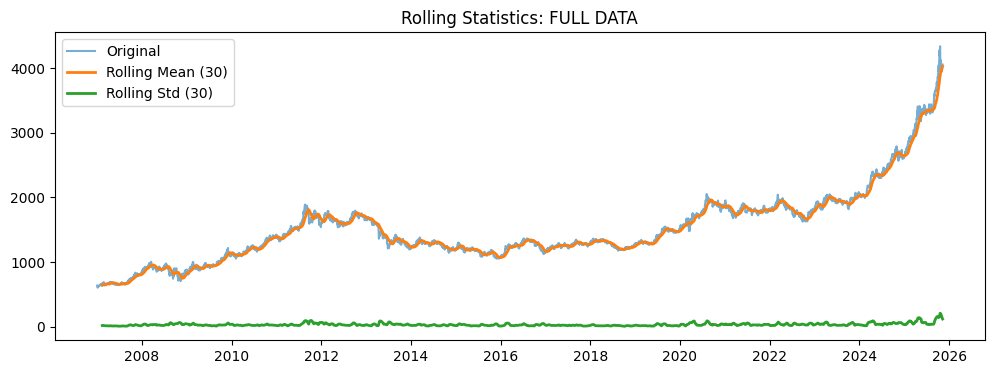

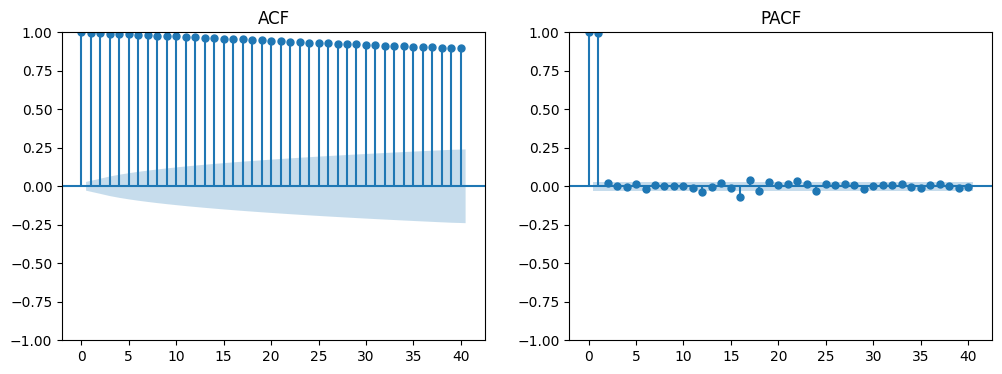


STATISTICAL ANALYSIS: REGIME 1

--- BASIC STATISTICS ---
Mean: 942.339
Std: 207.785
Coeff of Variation: 0.220

--- DISTRIBUTION SHAPE ---
Skewness: 0.402
Kurtosis: -0.691
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 0.9424
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


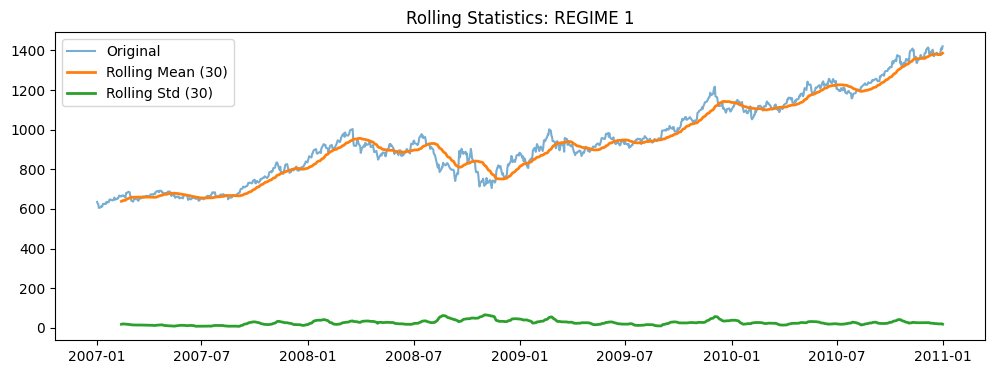

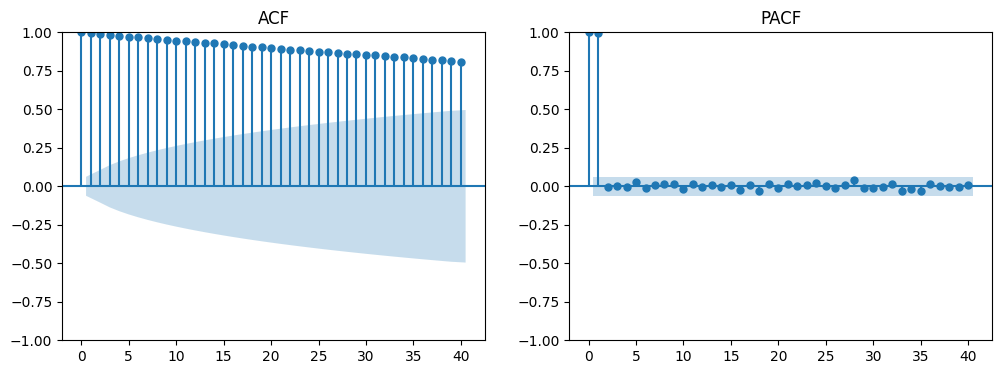


STATISTICAL ANALYSIS: REGIME 2

--- BASIC STATISTICS ---
Mean: 1360.176
Std: 181.080
Coeff of Variation: 0.133

--- DISTRIBUTION SHAPE ---
Skewness: 0.842
Kurtosis: -0.277
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 0.4534
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


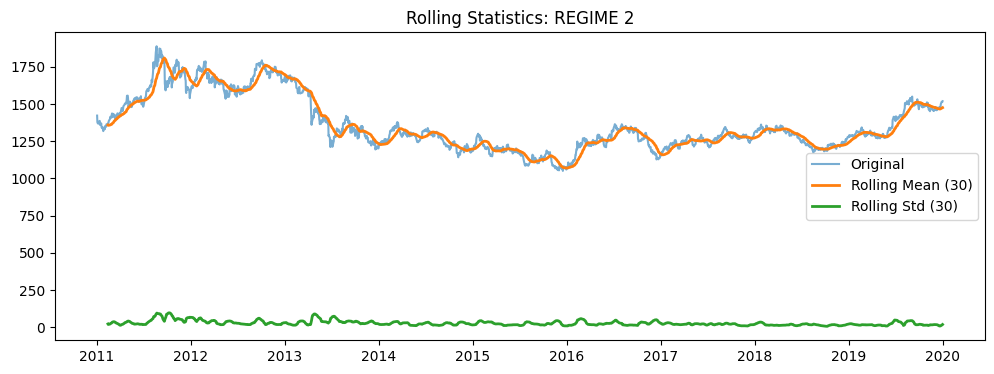

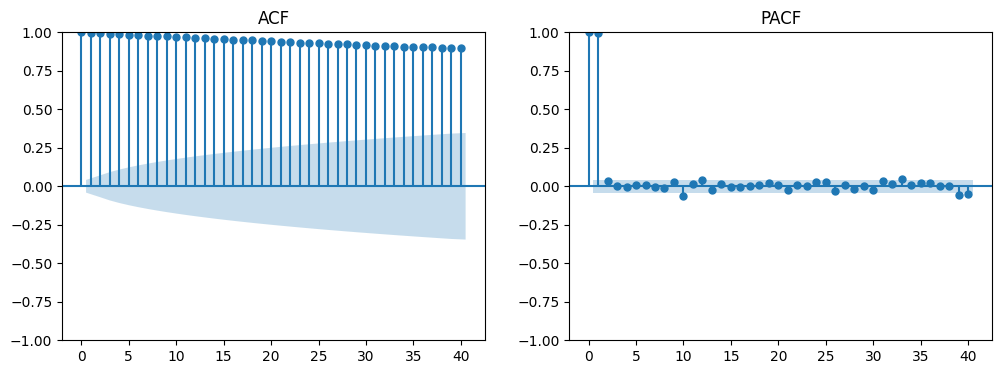


STATISTICAL ANALYSIS: REGIME 3

--- BASIC STATISTICS ---
Mean: 1785.392
Std: 105.442
Coeff of Variation: 0.059

--- DISTRIBUTION SHAPE ---
Skewness: -0.529
Kurtosis: 0.247
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 0.1295
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


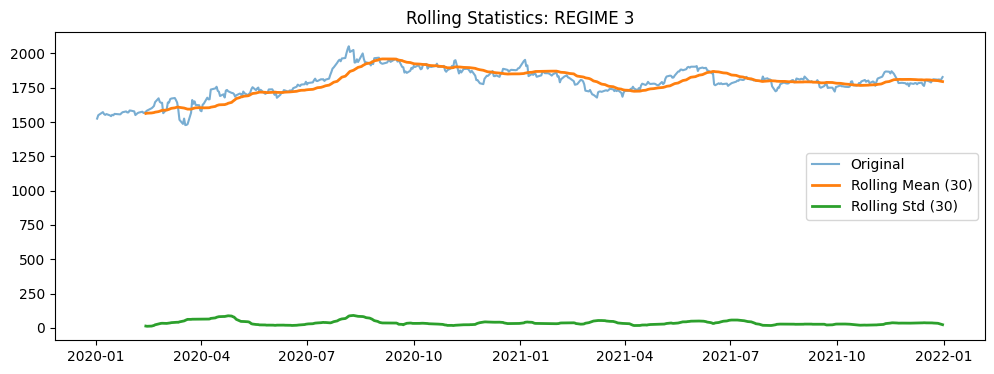

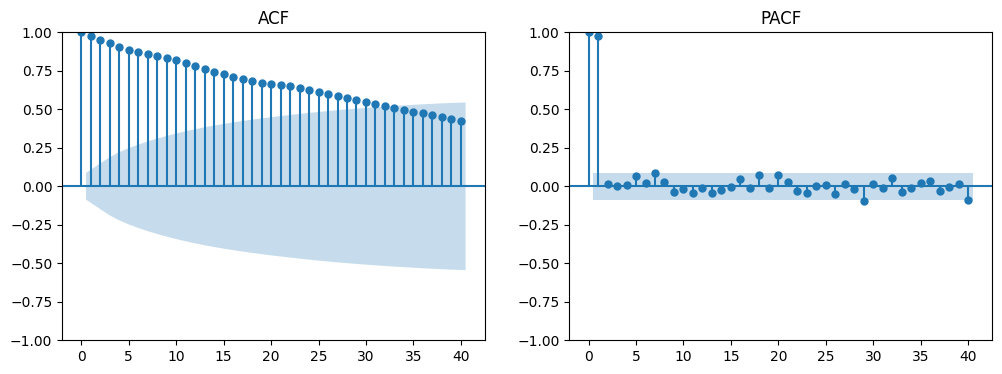


STATISTICAL ANALYSIS: REGIME 4

--- BASIC STATISTICS ---
Mean: 2329.980
Std: 617.291
Coeff of Variation: 0.265

--- DISTRIBUTION SHAPE ---
Skewness: 1.128
Kurtosis: 0.300
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 0.9988
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


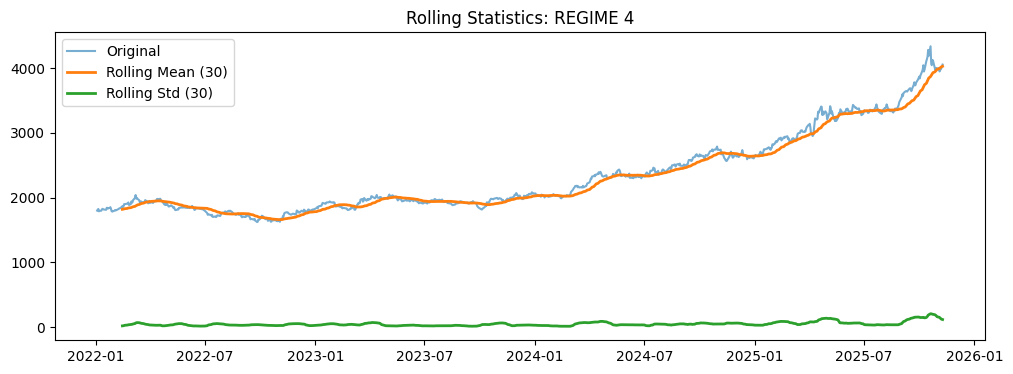

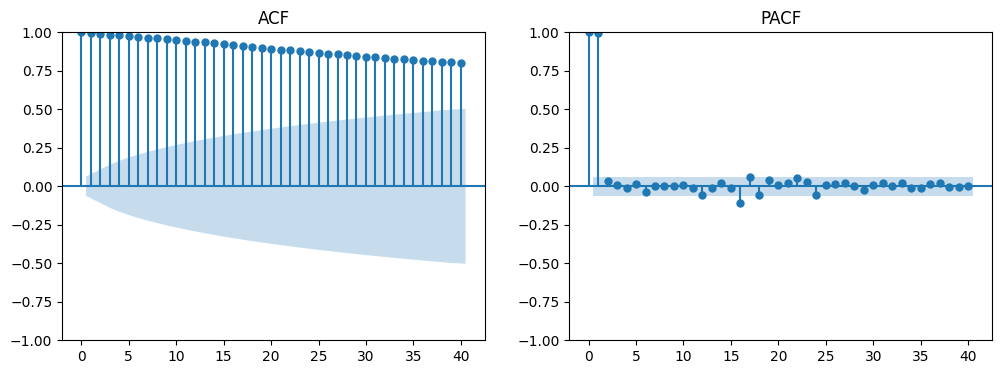

In [4]:
analyze_timeseries(df,  target="Close", name="FULL DATA")
analyze_timeseries(df1, target="Close", name="REGIME 1")
analyze_timeseries(df2, target="Close", name="REGIME 2")
analyze_timeseries(df3, target="Close", name="REGIME 3")
analyze_timeseries(df4, target="Close", name="REGIME 4")


In [6]:
def get_stats(df, target="Close"):
    s = df[target].dropna()

    stats = {}

    # Basic statistics
    stats["Mean"] = s.mean()
    stats["Std"]  = s.std()
    stats["CV"]   = s.std() / s.mean()

    # Distribution shape
    stats["Skewness"] = skew(s)
    stats["Kurtosis"] = kurtosis(s, fisher=True)

    # Normality
    stats["JB_pvalue"] = jarque_bera(s)[1]

    # Stationarity
    stats["ADF_pvalue"] = adfuller(s)[1]

    try:
        stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
    except:
        stats["KPSS_pvalue"] = np.nan

    return stats


In [7]:
results = pd.DataFrame({
    "FULL_DATA": get_stats(df),
    "DF1": get_stats(df1),
    "DF2": get_stats(df2),
    "DF3": get_stats(df3),
    "DF4": get_stats(df4)
})

results = results.round(4)
results


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values availa

,FULL_DATA,DF1,DF2,DF3,DF4
Mean,1514.8330,942.3389,1360.1763,1785.3923,2329.9802
Std,573.2113,207.7849,181.0798,105.4418,617.2911
CV,0.3784,0.2205,0.1331,0.0591,0.2649
Skewness,1.5756,0.4022,0.8417,-0.5287,1.1281
Kurtosis,3.6569,-0.6914,-0.2767,0.2472,0.3003
JB_pvalue,0.0000,0.0000,0.0000,0.0000,0.0000
ADF_pvalue,1.0000,0.9424,0.4534,0.1295,0.9988
KPSS_pvalue,0.0100,0.0100,0.0100,0.0100,0.0100
